In [2]:
import pandas as pd

cases =pd.read_csv("weekly_cases_per_million.csv")

print(cases.shape)
cases.columns
cases.head

(1143, 232)


<bound method NDFrame.head of             date    World  Afghanistan  Africa  Albania  Algeria  Andorra  \
0     2020-01-22      NaN          NaN     NaN      NaN      NaN      NaN   
1     2020-01-23      NaN          NaN     NaN      NaN      NaN      NaN   
2     2020-01-24      NaN          NaN     NaN      NaN      NaN      NaN   
3     2020-01-25      NaN          NaN     NaN      NaN      NaN      NaN   
4     2020-01-26      NaN          NaN     NaN      NaN      NaN      NaN   
...          ...      ...          ...     ...      ...      ...      ...   
1138  2023-03-05  123.610        2.820   3.704   17.239    0.824  112.721   
1139  2023-03-06  115.606        2.383   2.824   16.536    0.824  112.721   
1140  2023-03-07  113.053        2.772   2.706   12.666    1.091  112.721   
1141  2023-03-08  107.891        2.699   3.283   12.314    1.024  187.869   
1142  2023-03-09  106.230        2.261   3.086   17.239    0.735  187.869   

      Angola  Anguilla  Antigua and Barbuda  

change the format 

In [3]:
cases_long = cases.melt(
    id_vars="date",
    var_name="location",
    value_name="weekly_cases"
)

print(cases_long.shape)
cases_long.head()

(264033, 3)


,date,location,weekly_cases
0,2020-01-22,World,NaN
1,2020-01-23,World,NaN
2,2020-01-24,World,NaN
3,2020-01-25,World,NaN
4,2020-01-26,World,NaN


Convert date to proper datetime

In [4]:
cases_long["date"] = pd.to_datetime(cases_long["date"])

print(cases_long.dtypes)
print(cases_long["date"].min())
print(cases_long["date"].max())

date            datetime64[ns]
location                object
weekly_cases           float64
dtype: object
2020-01-22 00:00:00
2023-03-09 00:00:00


In [5]:
deaths = pd.read_csv("weekly_deaths.csv")

print(deaths.shape)
print(deaths.columns)
deaths.head()

(1143, 232)
Index(['date', 'World', 'Afghanistan', 'Africa', 'Albania', 'Algeria',
       'Andorra', 'Angola', 'Anguilla', 'Antigua and Barbuda',
       ...
       'Uruguay', 'Uzbekistan', 'Vanuatu', 'Vatican', 'Venezuela', 'Vietnam',
       'Wallis and Futuna', 'Yemen', 'Zambia', 'Zimbabwe'],
      dtype='object', length=232)


,date,World,Afghanistan,Africa,Albania,Algeria,Andorra,Angola,Anguilla,Antigua and Barbuda,...,Uruguay,Uzbekistan,Vanuatu,Vatican,Venezuela,Vietnam,Wallis and Futuna,Yemen,Zambia,Zimbabwe
0,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2020-01-23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2020-01-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2020-01-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2020-01-26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
deaths_long = deaths.melt(
    id_vars="date",
    var_name="location",
    value_name="weekly_deaths"
)

deaths_long["date"] = pd.to_datetime(deaths_long["date"])

print(deaths_long.shape)
deaths_long.head()

(264033, 3)


,date,location,weekly_deaths
0,2020-01-22,World,NaN
1,2020-01-23,World,NaN
2,2020-01-24,World,NaN
3,2020-01-25,World,NaN
4,2020-01-26,World,NaN


In [7]:
covid = pd.merge(
    cases_long,
    deaths_long,
    on=["date", "location"],
    how="outer"
)

print(covid.shape)
covid.head()

(264033, 4)


,date,location,weekly_cases,weekly_deaths
0,2020-01-22,Afghanistan,NaN,NaN
1,2020-01-22,Africa,NaN,NaN
2,2020-01-22,Albania,NaN,NaN
3,2020-01-22,Algeria,NaN,NaN
4,2020-01-22,Andorra,NaN,NaN


In [8]:
vaccinations = pd.read_csv("vaccinations.csv")

print(vaccinations.shape)
print(vaccinations.columns)
vaccinations.head()

(196246, 16)
Index(['location', 'iso_code', 'date', 'total_vaccinations',
       'people_vaccinated', 'people_fully_vaccinated', 'total_boosters',
       'daily_vaccinations_raw', 'daily_vaccinations',
       'total_vaccinations_per_hundred', 'people_vaccinated_per_hundred',
       'people_fully_vaccinated_per_hundred', 'total_boosters_per_hundred',
       'daily_vaccinations_per_million', 'daily_people_vaccinated',
       'daily_people_vaccinated_per_hundred'],
      dtype='object')


,location,iso_code,date,total_vaccinations,people_vaccinated,people_fully_vaccinated,total_boosters,daily_vaccinations_raw,daily_vaccinations,total_vaccinations_per_hundred,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred,total_boosters_per_hundred,daily_vaccinations_per_million,daily_people_vaccinated,daily_people_vaccinated_per_hundred
0,Afghanistan,AFG,2021-02-22,0.0,0.0,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,AFG,2021-02-23,NaN,NaN,NaN,NaN,NaN,1367.0,NaN,NaN,NaN,NaN,33.0,1367.0,0.003
2,Afghanistan,AFG,2021-02-24,NaN,NaN,NaN,NaN,NaN,1367.0,NaN,NaN,NaN,NaN,33.0,1367.0,0.003
3,Afghanistan,AFG,2021-02-25,NaN,NaN,NaN,NaN,NaN,1367.0,NaN,NaN,NaN,NaN,33.0,1367.0,0.003
4,Afghanistan,AFG,2021-02-26,NaN,NaN,NaN,NaN,NaN,1367.0,NaN,NaN,NaN,NaN,33.0,1367.0,0.003


Prepare vaccination data

In [9]:
vacc = vaccinations[
    [
        "location",
        "iso_code",
        "date",
        "total_vaccinations",
        "people_vaccinated",
        "people_fully_vaccinated",
        "total_boosters",
        "people_vaccinated_per_hundred",
        "people_fully_vaccinated_per_hundred",
        "daily_vaccinations"
    ]
].copy()

vacc["date"] = pd.to_datetime(vacc["date"])

print(vacc.shape)
print(vacc["date"].min())
print(vacc["date"].max())
vacc.head()

(196246, 10)
2020-12-02 00:00:00
2024-08-14 00:00:00


,location,iso_code,date,total_vaccinations,people_vaccinated,people_fully_vaccinated,total_boosters,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred,daily_vaccinations
0,Afghanistan,AFG,2021-02-22,0.0,0.0,NaN,NaN,0.0,NaN,NaN
1,Afghanistan,AFG,2021-02-23,NaN,NaN,NaN,NaN,NaN,NaN,1367.0
2,Afghanistan,AFG,2021-02-24,NaN,NaN,NaN,NaN,NaN,NaN,1367.0
3,Afghanistan,AFG,2021-02-25,NaN,NaN,NaN,NaN,NaN,NaN,1367.0
4,Afghanistan,AFG,2021-02-26,NaN,NaN,NaN,NaN,NaN,NaN,1367.0


In [10]:
covid_full = pd.merge(
    covid,
    vacc,
    on=["location", "date"],
    how="left"
)

print(covid_full.shape)
print(covid_full.columns)
covid_full.head()

(264033, 12)
Index(['date', 'location', 'weekly_cases', 'weekly_deaths', 'iso_code',
       'total_vaccinations', 'people_vaccinated', 'people_fully_vaccinated',
       'total_boosters', 'people_vaccinated_per_hundred',
       'people_fully_vaccinated_per_hundred', 'daily_vaccinations'],
      dtype='object')


,date,location,weekly_cases,weekly_deaths,iso_code,total_vaccinations,people_vaccinated,people_fully_vaccinated,total_boosters,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred,daily_vaccinations
0,2020-01-22,Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2020-01-22,Africa,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2020-01-22,Albania,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2020-01-22,Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2020-01-22,Andorra,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


check data quality after merge

In [11]:
print("Duplicates:", covid_full.duplicated(subset=["date", "location"]).sum())

print("\nMissing values:")
print(covid_full.isnull().sum())

print("\nUnique locations:", covid_full["location"].nunique())

print("\nNegative cases:", (covid_full["weekly_cases"] < 0).sum())
print("Negative deaths:", (covid_full["weekly_deaths"] < 0).sum())

Duplicates: 0

Missing values:
date                                        0
location                                    0
weekly_cases                            18284
weekly_deaths                           36711
iso_code                               108937
total_vaccinations                     195352
people_vaccinated                      198235
people_fully_vaccinated                201850
total_boosters                         224777
people_vaccinated_per_hundred          198235
people_fully_vaccinated_per_hundred    201850
daily_vaccinations                     109671
dtype: int64

Unique locations: 231

Negative cases: 0
Negative deaths: 0


separate countries from aggregate regions

In [12]:
covid_full.loc[
    covid_full["iso_code"].isna(),
    "location"
].drop_duplicates().sort_values().tolist()

['Afghanistan',
 'Africa',
 'Albania',
 'Algeria',
 'Andorra',
 'Angola',
 'Anguilla',
 'Antigua and Barbuda',
 'Argentina',
 'Armenia',
 'Aruba',
 'Asia',
 'Australia',
 'Austria',
 'Azerbaijan',
 'Bahamas',
 'Bahrain',
 'Bangladesh',
 'Barbados',
 'Belarus',
 'Belgium',
 'Belize',
 'Benin',
 'Bermuda',
 'Bhutan',
 'Bolivia',
 'Bonaire Sint Eustatius and Saba',
 'Bosnia and Herzegovina',
 'Botswana',
 'Brazil',
 'British Virgin Islands',
 'Brunei',
 'Bulgaria',
 'Burkina Faso',
 'Burundi',
 'Cambodia',
 'Cameroon',
 'Canada',
 'Cape Verde',
 'Cayman Islands',
 'Central African Republic',
 'Chad',
 'Chile',
 'China',
 'Colombia',
 'Comoros',
 'Congo',
 'Cook Islands',
 'Costa Rica',
 "Cote d'Ivoire",
 'Croatia',
 'Cuba',
 'Curacao',
 'Cyprus',
 'Czechia',
 'Democratic Republic of Congo',
 'Denmark',
 'Djibouti',
 'Dominica',
 'Dominican Republic',
 'Ecuador',
 'Egypt',
 'El Salvador',
 'Equatorial Guinea',
 'Eritrea',
 'Estonia',
 'Eswatini',
 'Ethiopia',
 'Europe',
 'European Union',


remove known aggregate regions

In [13]:
aggregate_locations = [
    "World",
    "Africa",
    "Asia",
    "Europe",
    "European Union",
    "North America",
    "South America",
    "Oceania",
    "High income",
    "Upper middle income",
    "Lower middle income",
    "Low income"
]

countries_df = covid_full[
    ~covid_full["location"].isin(aggregate_locations)
].copy()

print("Rows:", countries_df.shape[0])
print("Unique locations:", countries_df["location"].nunique())

Rows: 250317
Unique locations: 219


handle missing case/death values carefully

In [14]:
print("Valid case rows:", countries_df["weekly_cases"].notna().sum())
print("Valid death rows:", countries_df["weekly_deaths"].notna().sum())

Valid case rows: 232183
Valid death rows: 213756


In [15]:
countries_df[["weekly_cases", "weekly_deaths"]].describe()

,weekly_cases,weekly_deaths
count,232183.000000,213756.000000
mean,1243.024115,223.725444
std,4742.163054,1107.114383
min,0.000000,0.000000
25%,5.148500,0.000000
50%,96.095000,5.000000
75%,822.529500,62.000000
max,254952.787000,72553.000000


In [16]:
india_check = countries_df[
    (countries_df["location"] == "India") &
    (countries_df["weekly_cases"].notna())
][["date", "weekly_cases", "weekly_deaths"]]

india_check.tail(15)

,date,weekly_cases,weekly_deaths
260663,2023-02-23,0.676,7.0
260894,2023-02-24,0.723,7.0
261125,2023-02-25,0.776,9.0
261356,2023-02-26,0.822,9.0
261587,2023-02-27,0.874,10.0
261818,2023-02-28,0.955,10.0
262049,2023-03-01,1.008,9.0
262280,2023-03-02,1.091,8.0
262511,2023-03-03,1.197,11.0
262742,2023-03-04,1.272,6.0


In [17]:
cases = pd.read_csv("weekly_cases.csv")

cases_long = cases.melt(
    id_vars="date",
    var_name="location",
    value_name="weekly_cases"
)

cases_long["date"] = pd.to_datetime(cases_long["date"])

In [18]:
cases_long[
    (cases_long["location"] == "India") &
    (cases_long["weekly_cases"].notna())
].tail(10)

,date,location,weekly_cases
110861,2023-02-28,India,1354.0
110862,2023-03-01,India,1429.0
110863,2023-03-02,India,1546.0
110864,2023-03-03,India,1697.0
110865,2023-03-04,India,1803.0
110866,2023-03-05,India,1899.0
110867,2023-03-06,India,1996.0
110868,2023-03-07,India,2082.0
110869,2023-03-08,India,2193.0
110870,2023-03-09,India,2350.0


In [19]:
covid = pd.merge(
    cases_long,
    deaths_long,
    on=["date", "location"],
    how="outer"
)

covid_full = pd.merge(
    covid,
    vacc,
    on=["location", "date"],
    how="left"
)

print(covid_full.shape)
covid_full.head()

(264033, 12)


,date,location,weekly_cases,weekly_deaths,iso_code,total_vaccinations,people_vaccinated,people_fully_vaccinated,total_boosters,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred,daily_vaccinations
0,2020-01-22,Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2020-01-22,Africa,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2020-01-22,Albania,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2020-01-22,Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2020-01-22,Andorra,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
aggregate_locations = [
    "World",
    "Africa",
    "Asia",
    "Europe",
    "European Union",
    "North America",
    "South America",
    "Oceania",
    "High income",
    "Upper middle income",
    "Lower middle income",
    "Low income"
]

countries_df = covid_full[
    ~covid_full["location"].isin(aggregate_locations)
].copy()

print(countries_df.shape)
print(countries_df["location"].nunique())

(250317, 12)
219


analysis with country case burden

In [21]:
top_peak_cases = (
    countries_df.groupby("location")["weekly_cases"]
    .max()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

top_peak_cases

,location,weekly_cases
0,United States,5648740.0
1,South Korea,2834983.0
2,India,2738624.0
3,France,2565883.0
4,Vietnam,1918177.0
5,Germany,1606389.0
6,Japan,1588685.0
7,Brazil,1324589.0
8,Russia,1320987.0
9,United Kingdom,1275408.0


peak weekly deaths

In [22]:
top_peak_deaths = (
    countries_df.groupby("location")["weekly_deaths"]
    .max()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

top_peak_deaths

,location,weekly_deaths
0,China,72553.0
1,India,29330.0
2,United States,23638.0
3,Brazil,21786.0
4,Indonesia,12525.0
5,Mexico,9994.0
6,United Kingdom,9739.0
7,Russia,8523.0
8,France,6826.0
9,Germany,6274.0


total reported cases by country

In [23]:
total_cases_country = (
    countries_df.groupby("location")["weekly_cases"]
    .sum(min_count=1)
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

total_cases_country

,location,weekly_cases
0,United States,725602643.0
1,India,312824071.0
2,France,280039707.0
3,Germany,267565285.0
4,Brazil,258146433.0
5,Japan,233035673.0
6,South Korea,214075910.0
7,Italy,179063794.0
8,United Kingdom,164361858.0
9,Russia,154280131.0


In [25]:
groupby("location")["weekly_cases"].sum()

NameError: name 'groupby' is not defined

find when each country's worst case week occurred

In [26]:
peak_case_dates = (
    countries_df.loc[
        countries_df.groupby("location")["weekly_cases"].idxmax(),
        ["location", "date", "weekly_cases"]
    ]
    .sort_values("weekly_cases", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

peak_case_dates

,location,date,weekly_cases
0,United States,2022-01-15,5648740.0
1,South Korea,2022-03-17,2834983.0
2,India,2021-05-08,2738624.0
3,France,2022-01-25,2565883.0
4,Vietnam,2022-03-18,1918177.0
5,Germany,2022-03-24,1606389.0
6,Japan,2022-08-24,1588685.0
7,Brazil,2022-01-29,1324589.0
8,Russia,2022-02-15,1320987.0
9,United Kingdom,2022-01-05,1275408.0


prepare vaccination coverage correctly

In [27]:
vacc_cols = [
    "total_vaccinations",
    "people_vaccinated",
    "people_fully_vaccinated",
    "total_boosters",
    "people_vaccinated_per_hundred",
    "people_fully_vaccinated_per_hundred"
]

countries_df = countries_df.sort_values(["location", "date"])

countries_df[vacc_cols] = (
    countries_df.groupby("location")[vacc_cols]
    .ffill()
)

In [28]:
countries_df[
    countries_df["location"] == "India"
][
    [
        "date",
        "people_vaccinated_per_hundred",
        "people_fully_vaccinated_per_hundred"
    ]
].tail(10)

,date,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred
261818,2023-02-28,72.49,67.17
262049,2023-03-01,72.49,67.17
262280,2023-03-02,72.49,67.17
262511,2023-03-03,72.49,67.17
262742,2023-03-04,72.49,67.17
262973,2023-03-05,72.49,67.17
263204,2023-03-06,72.49,67.17
263435,2023-03-07,72.49,67.17
263666,2023-03-08,72.49,67.17
263897,2023-03-09,72.50,67.17


compare vaccination coverage by country

In [29]:
latest_vaccination = (
    countries_df
    .sort_values("date")
    .groupby("location")
    .tail(1)
    [["location",
      "people_vaccinated_per_hundred",
      "people_fully_vaccinated_per_hundred"]]
    .dropna(subset=["people_vaccinated_per_hundred"])
    .sort_values("people_vaccinated_per_hundred", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

latest_vaccination

,location,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred
0,Gibraltar,129.07,126.89
1,United Arab Emirates,105.83,103.72
2,Qatar,105.81,105.81
3,Nauru,103.27,89.40
4,Brunei,100.43,99.45
5,Macao,97.71,92.28
6,Cuba,95.69,89.27
7,Portugal,95.33,86.73
8,Hong Kong,92.33,90.76
9,Chile,92.27,90.29


In [30]:
major_countries = [
    "United States",
    "India",
    "Brazil",
    "United Kingdom",
    "France",
    "Germany",
    "Japan",
    "South Korea",
    "China",
    "Russia"
]

major_vaccination = (
    countries_df[
        countries_df["location"].isin(major_countries)
    ]
    .sort_values("date")
    .groupby("location")
    .tail(1)
    [
        [
            "location",
            "people_vaccinated_per_hundred",
            "people_fully_vaccinated_per_hundred"
        ]
    ]
    .sort_values(
        "people_fully_vaccinated_per_hundred",
        ascending=False
    )
)

major_vaccination

,location,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred
263845,China,91.89,89.54
263995,South Korea,86.42,85.62
263907,Japan,84.46,83.37
263831,Brazil,87.96,81.70
263876,France,80.61,78.42
263881,Germany,77.81,76.24
264019,United Kingdom,79.71,75.19
264020,United States,81.22,69.37
263897,India,72.50,67.17
263973,Russia,61.09,54.97


In [31]:
comparison_2022 = (
    countries_df[
        (countries_df["location"].isin(major_countries)) &
        (countries_df["date"] <= "2022-12-31")
    ]
    .sort_values("date")
    .groupby("location")
    .tail(1)
    [
        [
            "location",
            "date",
            "weekly_deaths",
            "people_fully_vaccinated_per_hundred"
        ]
    ]
    .sort_values(
        "people_fully_vaccinated_per_hundred",
        ascending=False
    )
)

comparison_2022

,location,date,weekly_deaths,people_fully_vaccinated_per_hundred
248137,China,2022-12-31,8.0,89.35
248287,South Korea,2022-12-31,429.0,85.60
248199,Japan,2022-12-31,2247.0,83.22
248123,Brazil,2022-12-31,1201.0,81.22
248168,France,2022-12-31,810.0,78.38
248173,Germany,2022-12-31,854.0,76.23
248311,United Kingdom,2022-12-31,946.0,75.19
248312,United States,2022-12-31,2556.0,69.15
248189,India,2022-12-31,12.0,67.12
248265,Russia,2022-12-31,378.0,54.54


In [32]:
deaths_pm = pd.read_csv("weekly_deaths_per_million.csv")

print(deaths_pm.shape)
deaths_pm.head()

(1143, 232)


,date,World,Afghanistan,Africa,Albania,Algeria,Andorra,Angola,Anguilla,Antigua and Barbuda,...,Uruguay,Uzbekistan,Vanuatu,Vatican,Venezuela,Vietnam,Wallis and Futuna,Yemen,Zambia,Zimbabwe
0,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2020-01-23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2020-01-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2020-01-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2020-01-26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
deaths_pm_long = deaths_pm.melt(
    id_vars="date",
    var_name="location",
    value_name="weekly_deaths_per_million"
)

deaths_pm_long["date"] = pd.to_datetime(deaths_pm_long["date"])

print(deaths_pm_long.shape)
deaths_pm_long.head()

(264033, 3)


,date,location,weekly_deaths_per_million
0,2020-01-22,World,NaN
1,2020-01-23,World,NaN
2,2020-01-24,World,NaN
3,2020-01-25,World,NaN
4,2020-01-26,World,NaN


In [34]:
countries_df = pd.merge(
    countries_df,
    deaths_pm_long,
    on=["date", "location"],
    how="left"
)

print(countries_df.shape)
countries_df[
    ["date", "location", "weekly_deaths", "weekly_deaths_per_million"]
].head()

(250317, 13)


,date,location,weekly_deaths,weekly_deaths_per_million
0,2020-01-22,Afghanistan,NaN,NaN
1,2020-01-23,Afghanistan,NaN,NaN
2,2020-01-24,Afghanistan,NaN,NaN
3,2020-01-25,Afghanistan,NaN,NaN
4,2020-01-26,Afghanistan,NaN,NaN


make the fair vaccination vs death comparison

In [35]:
comparison_2022_pm = (
    countries_df[
        (countries_df["location"].isin(major_countries)) &
        (countries_df["date"] <= "2022-12-31")
    ]
    .sort_values("date")
    .groupby("location")
    .tail(1)
    [
        [
            "location",
            "date",
            "weekly_deaths_per_million",
            "people_fully_vaccinated_per_hundred"
        ]
    ]
    .sort_values(
        "people_fully_vaccinated_per_hundred",
        ascending=False
    )
)

comparison_2022_pm

,location,date,weekly_deaths_per_million,people_fully_vaccinated_per_hundred
47937,China,2022-12-31,0.006,89.35
210243,South Korea,2022-12-31,8.279,85.60
115374,Japan,2022-12-31,18.128,83.22
31935,Brazil,2022-12-31,5.578,81.22
81084,France,2022-12-31,11.945,78.38
86799,Germany,2022-12-31,10.244,76.23
237675,United Kingdom,2022-12-31,14.013,75.19
238818,United States,2022-12-31,7.556,69.15
103944,India,2022-12-31,0.008,67.12
186240,Russia,2022-12-31,2.612,54.54


In [36]:
comparison_avg_2022 = (
    countries_df[
        (countries_df["location"].isin(major_countries)) &
        (countries_df["date"].between("2022-01-01", "2022-12-31"))
    ]
    .groupby("location")
    .agg(
        avg_weekly_deaths_per_million=("weekly_deaths_per_million", "mean"),
        avg_fully_vaccinated_per_hundred=("people_fully_vaccinated_per_hundred", "mean")
    )
    .reset_index()
    .sort_values("avg_fully_vaccinated_per_hundred", ascending=False)
)

comparison_avg_2022

,location,avg_weekly_deaths_per_million,avg_fully_vaccinated_per_hundred
1,China,0.009157,88.033123
7,South Korea,9.847652,85.223178
5,Japan,5.867058,82.222082
2,France,10.886934,77.780027
0,Brazil,6.661058,76.844247
3,Germany,11.569351,75.612137
8,United Kingdom,10.910682,74.021699
9,United States,15.409545,67.145562
4,India,0.678384,61.819452
6,Russia,11.351310,51.441890


In [37]:
correlation = comparison_avg_2022[
    [
        "avg_fully_vaccinated_per_hundred",
        "avg_weekly_deaths_per_million"
    ]
].corr()

correlation

,avg_fully_vaccinated_per_hundred,avg_weekly_deaths_per_million
avg_fully_vaccinated_per_hundred,1.000000,-0.267374
avg_weekly_deaths_per_million,-0.267374,1.000000


In [38]:
wave_countries = [
    "United States",
    "India",
    "Brazil",
    "United Kingdom",
    "France"
]

wave_data = countries_df[
    countries_df["location"].isin(wave_countries)
][["date", "location", "weekly_cases"]].dropna()

wave_data.head()

,date,location,weekly_cases
30901,2020-03-02,Brazil,2.0
30902,2020-03-03,Brazil,2.0
30903,2020-03-04,Brazil,3.0
30904,2020-03-05,Brazil,3.0
30905,2020-03-06,Brazil,12.0


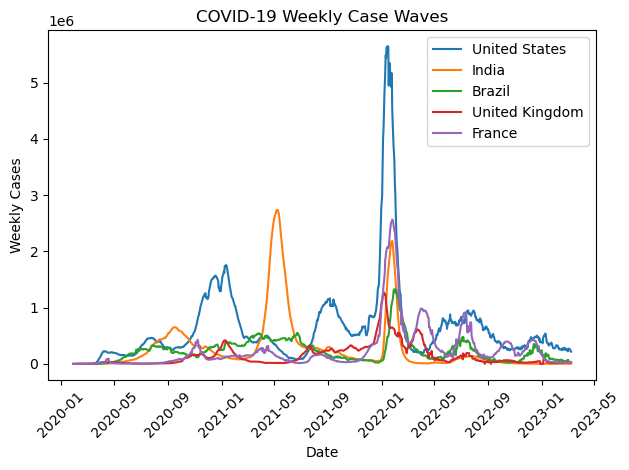

In [39]:
import matplotlib.pyplot as plt

for country in wave_countries:
    country_data = wave_data[wave_data["location"] == country]
    plt.plot(
        country_data["date"],
        country_data["weekly_cases"],
        label=country
    )

plt.title("COVID-19 Weekly Case Waves")
plt.xlabel("Date")
plt.ylabel("Weekly Cases")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

weekly deaths trend

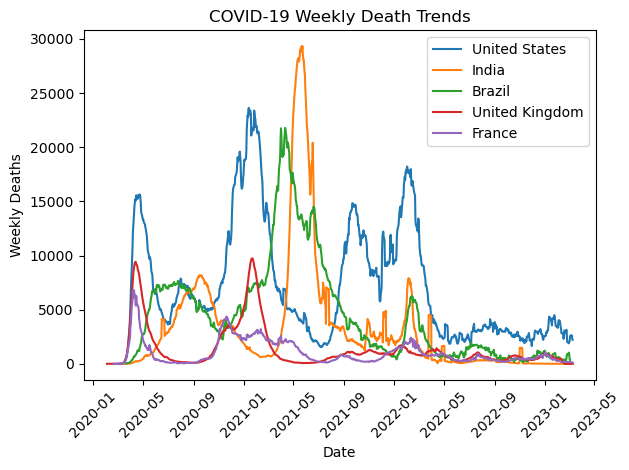

In [40]:
death_wave_data = countries_df[
    countries_df["location"].isin(wave_countries)
][["date", "location", "weekly_deaths"]].dropna()

for country in wave_countries:
    country_data = death_wave_data[
        death_wave_data["location"] == country
    ]
    
    plt.plot(
        country_data["date"],
        country_data["weekly_deaths"],
        label=country
    )

plt.title("COVID-19 Weekly Death Trends")
plt.xlabel("Date")
plt.ylabel("Weekly Deaths")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

deaths per million trend

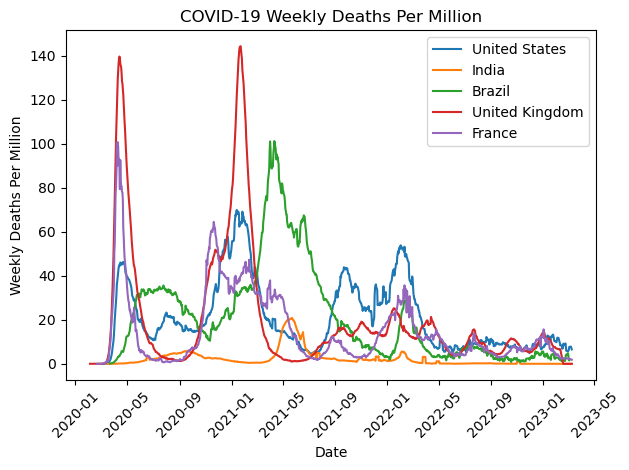

In [41]:
death_pm_wave_data = countries_df[
    countries_df["location"].isin(wave_countries)
][["date", "location", "weekly_deaths_per_million"]].dropna()

for country in wave_countries:
    country_data = death_pm_wave_data[
        death_pm_wave_data["location"] == country
    ]

    plt.plot(
        country_data["date"],
        country_data["weekly_deaths_per_million"],
        label=country
    )

plt.title("COVID-19 Weekly Deaths Per Million")
plt.xlabel("Date")
plt.ylabel("Weekly Deaths Per Million")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

vaccination rollout trend

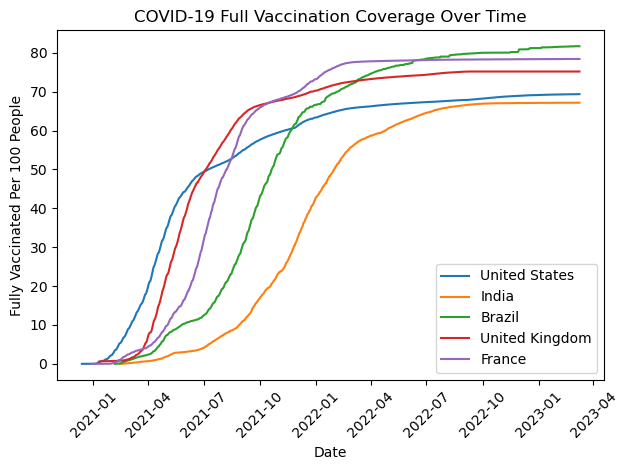

In [42]:
vacc_trend = countries_df[
    countries_df["location"].isin(wave_countries)
][
    [
        "date",
        "location",
        "people_fully_vaccinated_per_hundred"
    ]
].dropna()

for country in wave_countries:
    country_data = vacc_trend[
        vacc_trend["location"] == country
    ]

    plt.plot(
        country_data["date"],
        country_data["people_fully_vaccinated_per_hundred"],
        label=country
    )

plt.title("COVID-19 Full Vaccination Coverage Over Time")
plt.xlabel("Date")
plt.ylabel("Fully Vaccinated Per 100 People")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

build one combined comparison table for insights

In [43]:
summary_table = (
    countries_df[
        countries_df["location"].isin(wave_countries)
    ]
    .groupby("location")
    .agg(
        peak_weekly_cases=("weekly_cases", "max"),
        peak_weekly_deaths_per_million=("weekly_deaths_per_million", "max"),
        latest_fully_vaccinated_per_hundred=(
            "people_fully_vaccinated_per_hundred",
            "last"
        )
    )
    .reset_index()
)

summary_table

,location,peak_weekly_cases,peak_weekly_deaths_per_million,latest_fully_vaccinated_per_hundred
0,Brazil,1324589.0,101.183,81.70
1,France,2565883.0,100.659,78.42
2,India,2738624.0,20.696,67.17
3,United Kingdom,1275408.0,144.262,75.19
4,United States,5648740.0,69.875,69.37


In [44]:
cases_pm = pd.read_csv("weekly_cases_per_million.csv")

cases_pm_long = cases_pm.melt(
    id_vars="date",
    var_name="location",
    value_name="weekly_cases_per_million"
)

cases_pm_long["date"] = pd.to_datetime(cases_pm_long["date"])

print(cases_pm_long.shape)
cases_pm_long.head()

(264033, 3)


,date,location,weekly_cases_per_million
0,2020-01-22,World,NaN
1,2020-01-23,World,NaN
2,2020-01-24,World,NaN
3,2020-01-25,World,NaN
4,2020-01-26,World,NaN


In [45]:
countries_df = pd.merge(
    countries_df,
    cases_pm_long,
    on=["date", "location"],
    how="left"
)

print(countries_df.shape)

countries_df[
    [
        "date",
        "location",
        "weekly_cases",
        "weekly_cases_per_million",
        "weekly_deaths_per_million"
    ]
].head()

(250317, 14)


,date,location,weekly_cases,weekly_cases_per_million,weekly_deaths_per_million
0,2020-01-22,Afghanistan,NaN,NaN,NaN
1,2020-01-23,Afghanistan,NaN,NaN,NaN
2,2020-01-24,Afghanistan,NaN,NaN,NaN
3,2020-01-25,Afghanistan,NaN,NaN,NaN
4,2020-01-26,Afghanistan,NaN,NaN,NaN


In [46]:
peak_cases_pm = (
    countries_df.groupby("location")["weekly_cases_per_million"]
    .max()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

peak_cases_pm

,location,weekly_cases_per_million
0,Saint Helena,254952.787
1,Falkland Islands,244409.366
2,Wallis and Futuna,228872.025
3,Marshall Islands,221936.384
4,Nauru,212512.804
5,Tuvalu,137009.263
6,Faeroe Islands,103770.921
7,Micronesia (country),87748.953
8,Montserrat,86109.223
9,Israel,75493.280


In [47]:
major_cases_pm = (
    countries_df[
        countries_df["location"].isin(major_countries)
    ]
    .groupby("location")["weekly_cases_per_million"]
    .max()
    .sort_values(ascending=False)
    .reset_index()
)

major_cases_pm

,location,weekly_cases_per_million
0,South Korea,54712.705
1,France,37837.627
2,Germany,19268.227
3,United Kingdom,18892.432
4,United States,16697.929
5,Japan,12816.969
6,Russia,9128.303
7,Brazil,6151.909
8,India,1932.456
9,China,200.250


Insight 1:

Raw counts and per-million metrics tell very different stories.

The United States had the highest raw peak weekly cases, but South Korea had the highest peak weekly cases per million among the selected major countries.

Insight 2:

COVID waves peaked at different times across countries

The wave analysis shows that major countries did not experience their largest outbreaks at the same time.

For example:
- United States peak weekly cases: 5,648,740 on 15 Jan 2022
- India: 2,738,624 on 8 May 2021
- France: 2,565,883 on 25 Jan 2022
- South Korea: 2,834,983 on 17 Mar 2022

This shows that the pandemic evolved in different waves by country, rather than as one uniform global event.

Insight 3:

Vaccination coverage and mortality showed only a weak relationship

For the selected major countries in 2022, the correlation between:
- average fully vaccinated per 100 people
- average weekly deaths per million

was about -0.27.

That means higher vaccination coverage was associated with somewhat lower death rates, but the relationship was weak, not strong.

For example:
- China had very high vaccination coverage and very low reported deaths per million.
- The United States and Russia had lower vaccination coverage and relatively higher death rates.
- But countries such as Germany, France, South Korea, and the UK still experienced notable death rates despite high vaccination coverage.

Interpretation:

Vaccination coverage alone does not explain mortality differences. Other factors such as outbreak timing, population structure, healthcare capacity, prior infection, reporting practices, and public-health measures also matter.

Insight 4 —

Per-million metrics are essential for fair country comparisons

Raw case and death totals can be misleading because countries have very different population sizes.

For example:
- United States had the highest raw peak weekly cases: 5,648,740
- But South Korea had the highest peak weekly cases per million among the selected major countries: 54,712.705
- India had a very large raw peak, but only 1,932.456 weekly cases per million

Interpretation:

The dashboard should always show both raw counts and population-normalized metrics such as cases per million and deaths per million.

Insight 5 —

Vaccination rollout differed significantly across countries

The vaccination trend showed clear differences in both speed and final coverage.

Among the five countries used in the main comparison:
- Brazil reached the highest latest full-vaccination coverage: 81.70 per 100
- France: 78.42
- United Kingdom: 75.19
- United States: 69.37
- India: 67.17

The United States and United Kingdom rolled out vaccination earlier, while Brazil and France eventually reached higher full-vaccination coverage.

Interpretation:

Countries followed different vaccination trajectories, so rollout timing is as important as final coverage.

In [48]:
powerbi_df = countries_df[
    [
        "date",
        "location",
        "weekly_cases",
        "weekly_deaths",
        "weekly_cases_per_million",
        "weekly_deaths_per_million",
        "people_vaccinated_per_hundred",
        "people_fully_vaccinated_per_hundred",
        "total_vaccinations",
        "people_vaccinated",
        "people_fully_vaccinated"
    ]
].copy()

powerbi_df.to_csv(
    "Day3_COVID_Global_Impact_Cleaned.csv",
    index=False
)

print(powerbi_df.shape)
powerbi_df.head()

(250317, 11)


,date,location,weekly_cases,weekly_deaths,weekly_cases_per_million,weekly_deaths_per_million,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred,total_vaccinations,people_vaccinated,people_fully_vaccinated
0,2020-01-22,Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2020-01-23,Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2020-01-24,Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2020-01-25,Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2020-01-26,Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
